In [1]:
# Lab 7: Keras MLP for Multiclass Classification

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.20.0
Libraries imported successfully!


In [2]:
# Load the Iris dataset
iris = load_iris()

# Convert the data into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the target/class column
df["target"] = iris.target

# Display the first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
# Basic information about the dataset

print("Number of samples:", df.shape[0])
print("Number of features:", len(iris.feature_names))
print("Feature names:", iris.feature_names)
print("Number of classes:", len(iris.target_names))
print("Class names:", iris.target_names)

print("\nDataset information:")
df.info()

Number of samples: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Number of classes: 3
Class names: ['setosa' 'versicolor' 'virginica']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [4]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [5]:
# Analyze class distribution

class_counts = df["target"].value_counts().sort_index()

for i, count in enumerate(class_counts):
    print(iris.target_names[i], ":", count)

setosa : 50
versicolor : 50
virginica : 50


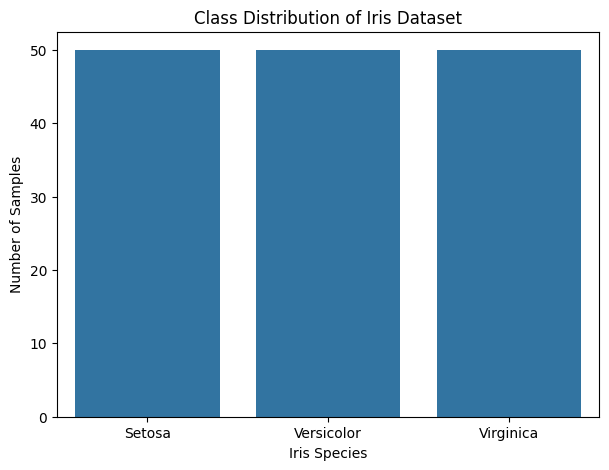

In [6]:
# Visualize class distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    x=df["target"].map({
        0: "Setosa",
        1: "Versicolor",
        2: "Virginica"
    })
)

plt.title("Class Distribution of Iris Dataset")
plt.xlabel("Iris Species")
plt.ylabel("Number of Samples")
plt.show()

In [7]:
# Separate input features and target variable

X = df[iris.feature_names]
y = df["target"]

print("Input features (X):")
print(X.head())

print("\nTarget variable (y):")
print(y.head())

Input features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target variable (y):
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [8]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [9]:
# Feature scaling using StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 scaled training samples:")
print(X_train_scaled[:5])

First 5 scaled training samples:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [11]:
# Build the baseline MLP model

model = keras.Sequential([
    layers.Input(shape=(4,)),

    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),

    layers.Dense(3, activation="softmax")
])

# Display the model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile the MLP model

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
# Train the baseline MLP model

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.0938 - loss: 1.1745 - val_accuracy: 0.0417 - val_loss: 1.1566
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1250 - loss: 1.1269 - val_accuracy: 0.0833 - val_loss: 1.1059
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1667 - loss: 1.0803 - val_accuracy: 0.2500 - val_loss: 1.0576
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2188 - loss: 1.0375 - val_accuracy: 0.2500 - val_loss: 1.0094
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4375 - loss: 0.9940 - val_accuracy: 0.6250 - val_loss: 0.9640
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6146 - loss: 0.9499 - val_accuracy: 0.5833 - val_loss: 0.9225
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6667 - loss: 0.9113 - val_accuracy: 0.5833 - val_loss: 0.8831
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6979 - loss: 0.8700 - val_accuracy: 0.5833 - val_loss: 0.8492

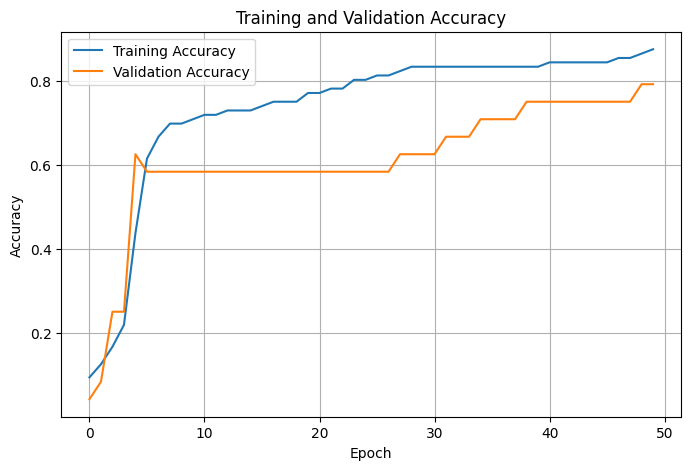

In [14]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [16]:
# Evaluate the model on the unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.4197402000427246
Test Accuracy: 0.800000011920929


In [17]:
# Generate predictions on the test set

y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate evaluation metrics

precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
Precision: 0.875
Recall: 0.7999999999999999
F1-score: 0.7802197802197802


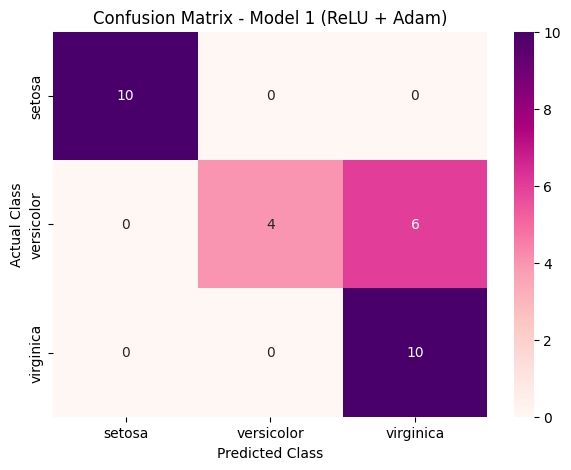

In [27]:
# Create and visualize the confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix - Model 1 (ReLU + Adam)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [19]:
# Model 2: MLP with Sigmoid activation

model_sigmoid = keras.Sequential([
    layers.Input(shape=(4,)),

    layers.Dense(16, activation="sigmoid"),
    layers.Dense(8, activation="sigmoid"),

    layers.Dense(3, activation="softmax")
])

model_sigmoid.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_sigmoid.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [60]:
# Train Model 2

history_sigmoid = model_sigmoid.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.6979 - loss: 0.7299 - val_accuracy: 0.5833 - val_loss: 0.7428
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6979 - loss: 0.7221 - val_accuracy: 0.5833 - val_loss: 0.7353
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6979 - loss: 0.7141 - val_accuracy: 0.5833 - val_loss: 0.7283
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6979 - loss: 0.7064 - val_accuracy: 0.5833 - val_loss: 0.7213
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6979 - loss: 0.6989 - val_accuracy: 0.5833 - val_loss: 0.7144
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6979 - loss: 0.6914 - val_accuracy: 0.5833 - val_loss: 0.7078
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6979 - loss: 0.6847 - val_accuracy: 0.5833 - val_loss: 0.7023
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6979 - loss: 0.6774 - val_accuracy: 0.5833 - val_loss: 0.6961


In [21]:
# Train Model 2

history_sigmoid = model_sigmoid.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.3542 - loss: 1.0988 - val_accuracy: 0.2500 - val_loss: 1.1127
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.3542 - loss: 1.0924 - val_accuracy: 0.2500 - val_loss: 1.1039
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3542 - loss: 1.0868 - val_accuracy: 0.2500 - val_loss: 1.0959
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.3646 - loss: 1.0820 - val_accuracy: 0.4167 - val_loss: 1.0905
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5417 - loss: 1.0769 - val_accuracy: 0.5833 - val_loss: 1.0825
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6667 - loss: 1.0711 - val_accuracy: 0.5833 - val_loss: 1.0767
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6771 - loss: 1.0661 - val_accuracy: 0.5833 - val_loss: 1.0709
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6875 - loss: 1.0610 - val_accuracy: 0.5833 - val_loss: 1.0650


In [22]:
# Evaluate Model 2 on the test dataset

test_loss_sigmoid, test_accuracy_sigmoid = model_sigmoid.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

# Generate predictions
y_pred_prob_sigmoid = model_sigmoid.predict(X_test_scaled, verbose=0)
y_pred_sigmoid = np.argmax(y_pred_prob_sigmoid, axis=1)

# Calculate metrics
precision_sigmoid = precision_score(
    y_test, y_pred_sigmoid, average="macro"
)

recall_sigmoid = recall_score(
    y_test, y_pred_sigmoid, average="macro"
)

f1_sigmoid = f1_score(
    y_test, y_pred_sigmoid, average="macro"
)

print("Model 2 - Sigmoid + Adam")
print("-------------------------")
print("Test Accuracy:", test_accuracy_sigmoid)
print("Precision:", precision_sigmoid)
print("Recall:", recall_sigmoid)
print("F1-score:", f1_sigmoid)

Model 2 - Sigmoid + Adam
-------------------------
Test Accuracy: 0.699999988079071
Precision: 0.8421052631578947
Recall: 0.7000000000000001
F1-score: 0.6238244514106583


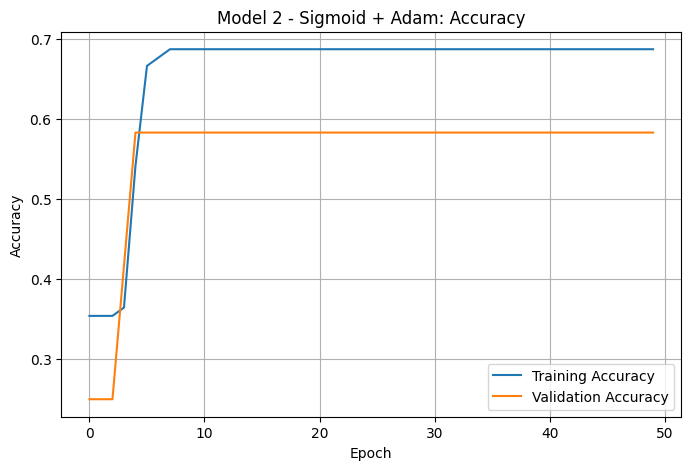

In [24]:
# Model 2 accuracy curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_sigmoid.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_sigmoid.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Model 2 - Sigmoid + Adam: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

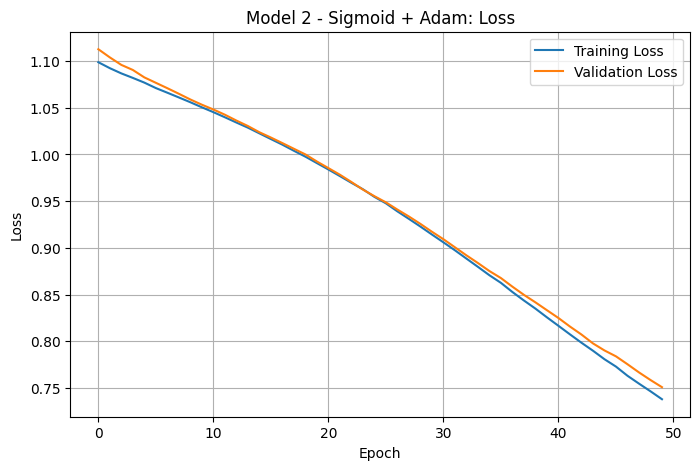

In [25]:
# Model 2 loss curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_sigmoid.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_sigmoid.history["val_loss"],
    label="Validation Loss"
)

plt.title("Model 2 - Sigmoid + Adam: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

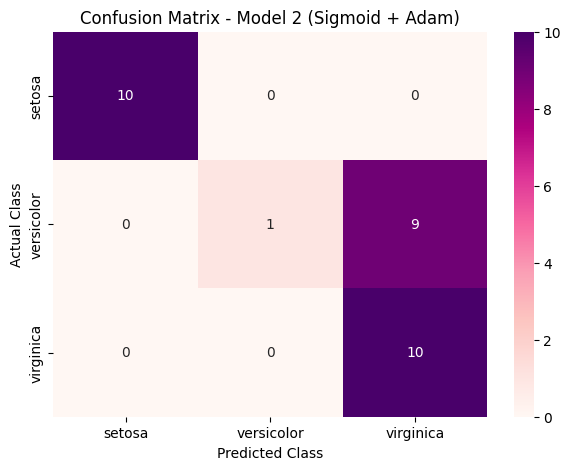

In [28]:
# Model 2 confusion matrix

cm_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_sigmoid,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix - Model 2 (Sigmoid + Adam)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [29]:
# 🎀 Model 3: Tanh + Adam

model_tanh = keras.Sequential([
    layers.Input(shape=(4,)),

    layers.Dense(16, activation="tanh"),
    layers.Dense(8, activation="tanh"),

    layers.Dense(3, activation="softmax")
])

model_tanh.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_tanh.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [30]:
#  Train Model 3

history_tanh = model_tanh.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 152ms/step - accuracy: 0.6146 - loss: 0.8742 - val_accuracy: 0.6250 - val_loss: 0.8616
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6875 - loss: 0.7974 - val_accuracy: 0.7500 - val_loss: 0.7988
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.7396 - loss: 0.7357 - val_accuracy: 0.7917 - val_loss: 0.7461
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7500 - loss: 0.6831 - val_accuracy: 0.7917 - val_loss: 0.7023
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7917 - loss: 0.6373 - val_accuracy: 0.7500 - val_loss: 0.6664
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8021 - loss: 0.6000 - val_accuracy: 0.7500 - val_loss: 0.6369
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8021 - loss: 0.5685 - val_accuracy: 0.7500 - val_loss: 0.6119
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8125 - loss: 0.5426 - val_accuracy: 0.7500 - val_loss: 0.5913

In [31]:
#  Evaluate Model 3

test_loss_tanh, test_accuracy_tanh = model_tanh.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

y_pred_prob_tanh = model_tanh.predict(
    X_test_scaled,
    verbose=0
)

y_pred_tanh = np.argmax(
    y_pred_prob_tanh,
    axis=1
)

precision_tanh = precision_score(
    y_test, y_pred_tanh, average="macro"
)

recall_tanh = recall_score(
    y_test, y_pred_tanh, average="macro"
)

f1_tanh = f1_score(
    y_test, y_pred_tanh, average="macro"
)

print("🎀 Model 3 - Tanh + Adam 🎀")
print("---------------------------")
print("Test Accuracy:", test_accuracy_tanh)
print("Precision:", precision_tanh)
print("Recall:", recall_tanh)
print("F1-score:", f1_tanh)

🎀 Model 3 - Tanh + Adam 🎀
---------------------------
Test Accuracy: 0.8333333134651184
Precision: 0.8498168498168498
Recall: 0.8333333333333334
F1-score: 0.8294970161977835


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128150 (\N{SPARKLING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


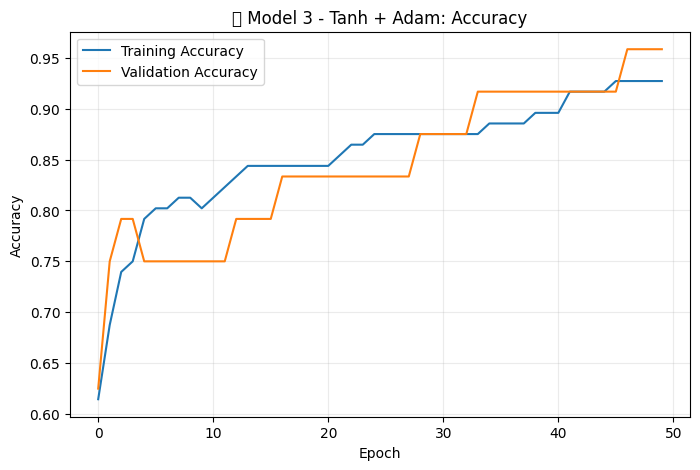

In [33]:
#  Model 3 - Accuracy Curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_tanh.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_tanh.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(" Model 3 - Tanh + Adam: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127872 (\N{RIBBON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


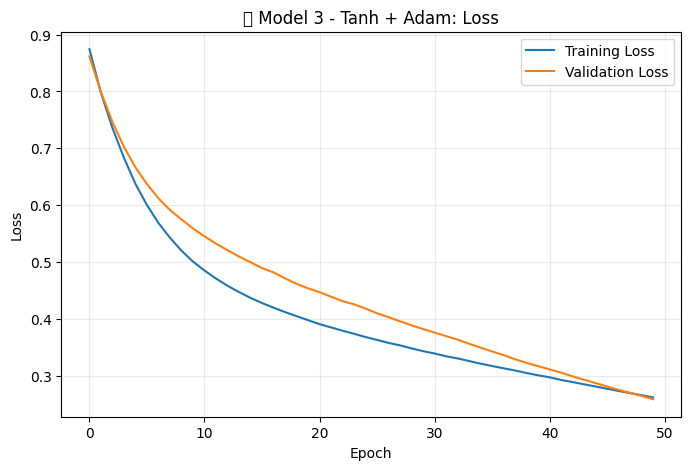

In [34]:
# 🎀 Model 3 - Loss Curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_tanh.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_tanh.history["val_loss"],
    label="Validation Loss"
)

plt.title("🎀 Model 3 - Tanh + Adam: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

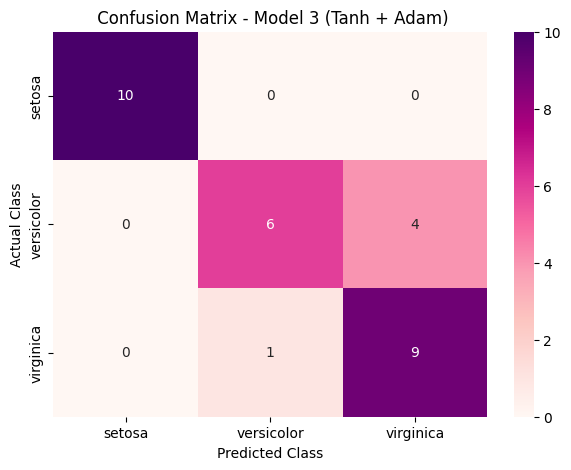

In [35]:
# 💎 Model 3 - Confusion Matrix

cm_tanh = confusion_matrix(y_test, y_pred_tanh)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tanh,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title(" Confusion Matrix - Model 3 (Tanh + Adam)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [42]:
# 💗 MODEL 4: ReLU + SGD

model_sgd = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_sgd.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_sgd = model_sgd.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

print("💗 Model 4 training completed!")

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 311ms/step - accuracy: 0.3229 - loss: 1.1807 - val_accuracy: 0.3333 - val_loss: 1.1374
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.3229 - loss: 1.1755 - val_accuracy: 0.3333 - val_loss: 1.1326
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.3229 - loss: 1.1704 - val_accuracy: 0.3333 - val_loss: 1.1280
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.3229 - loss: 1.1655 - val_accuracy: 0.3333 - val_loss: 1.1235
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3229 - loss: 1.1606 - val_accuracy: 0.3333 - val_loss: 1.1190
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.3229 - loss: 1.1557 - val_accuracy: 0.3333 - val_loss: 1.1146
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3229 - loss: 1.1509 - val_accuracy: 0.3333 - val_loss: 1.1102
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.3229 - loss: 1.1462 - val_accuracy: 0.3333 - val_loss: 1.1059

In [43]:
# 💗 Evaluate Model 4

test_loss_sgd, test_accuracy_sgd = model_sgd.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

y_pred_prob_sgd = model_sgd.predict(X_test_scaled, verbose=0)
y_pred_sgd = np.argmax(y_pred_prob_sgd, axis=1)

precision_sgd = precision_score(
    y_test, y_pred_sgd, average="macro"
)

recall_sgd = recall_score(
    y_test, y_pred_sgd, average="macro"
)

f1_sgd = f1_score(
    y_test, y_pred_sgd, average="macro"
)

print("💗 MODEL 4 — RELU + SGD 💗")
print("---------------------------")
print("Test Accuracy:", test_accuracy_sgd)
print("Precision:", precision_sgd)
print("Recall:", recall_sgd)
print("F1-score:", f1_sgd)

💗 MODEL 4 — RELU + SGD 💗
---------------------------
Test Accuracy: 0.3333333432674408
Precision: 0.12820512820512822
Recall: 0.3333333333333333
F1-score: 0.1851851851851852


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128151 (\N{GROWING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


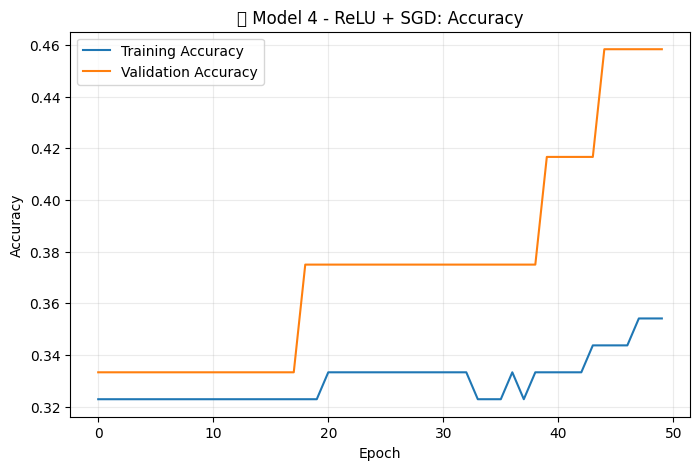

In [44]:
# 💗 Model 4 Accuracy Curve

plt.figure(figsize=(8, 5))

plt.plot(history_sgd.history["accuracy"], label="Training Accuracy")
plt.plot(history_sgd.history["val_accuracy"], label="Validation Accuracy")

plt.title("💗 Model 4 - ReLU + SGD: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128150 (\N{SPARKLING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


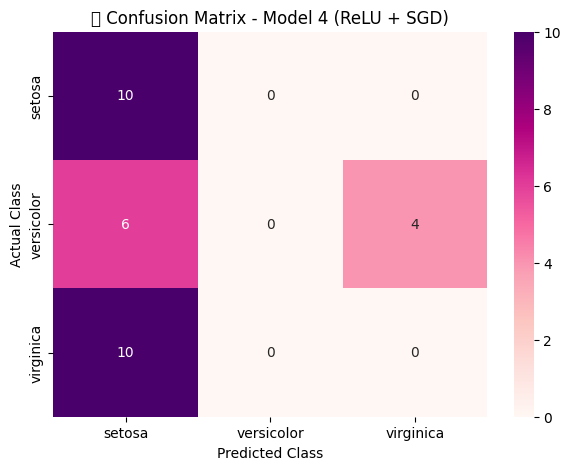

In [46]:
# 💎 Model 4 Confusion Matrix

cm_sgd = confusion_matrix(y_test, y_pred_sgd)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_sgd,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("💖 Confusion Matrix - Model 4 (ReLU + SGD)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [47]:
# 🎀 MODEL 5: ReLU + RMSprop

model_rmsprop = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_rmsprop.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_rmsprop = model_rmsprop.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

print("🎀 Model 5 training completed!")

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.2292 - loss: 1.3050 - val_accuracy: 0.2917 - val_loss: 1.1884
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2500 - loss: 1.2205 - val_accuracy: 0.2917 - val_loss: 1.1452
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2500 - loss: 1.1670 - val_accuracy: 0.3333 - val_loss: 1.1140
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2500 - loss: 1.1244 - val_accuracy: 0.3333 - val_loss: 1.0892
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3125 - loss: 1.0878 - val_accuracy: 0.4167 - val_loss: 1.0676
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4479 - loss: 1.0549 - val_accuracy: 0.5000 - val_loss: 1.0470
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.5729 - loss: 1.0267 - val_accuracy: 0.5417 - val_loss: 1.0292
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6354 - loss: 1.0027 - val_accuracy: 0.6250 - val_loss: 1.0144


In [48]:
# 🎀 Evaluate Model 5

test_loss_rmsprop, test_accuracy_rmsprop = model_rmsprop.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

y_pred_prob_rmsprop = model_rmsprop.predict(
    X_test_scaled,
    verbose=0
)

y_pred_rmsprop = np.argmax(
    y_pred_prob_rmsprop,
    axis=1
)

precision_rmsprop = precision_score(
    y_test, y_pred_rmsprop, average="macro"
)

recall_rmsprop = recall_score(
    y_test, y_pred_rmsprop, average="macro"
)

f1_rmsprop = f1_score(
    y_test, y_pred_rmsprop, average="macro"
)

print("🎀 MODEL 5 — RELU + RMSPROP 🎀")
print("--------------------------------")
print("Test Accuracy:", test_accuracy_rmsprop)
print("Precision:", precision_rmsprop)
print("Recall:", recall_rmsprop)
print("F1-score:", f1_rmsprop)

🎀 MODEL 5 — RELU + RMSPROP 🎀
--------------------------------
Test Accuracy: 0.7333333492279053
Precision: 0.8324420677361855
Recall: 0.7333333333333334
F1-score: 0.6754850088183421


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127872 (\N{RIBBON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


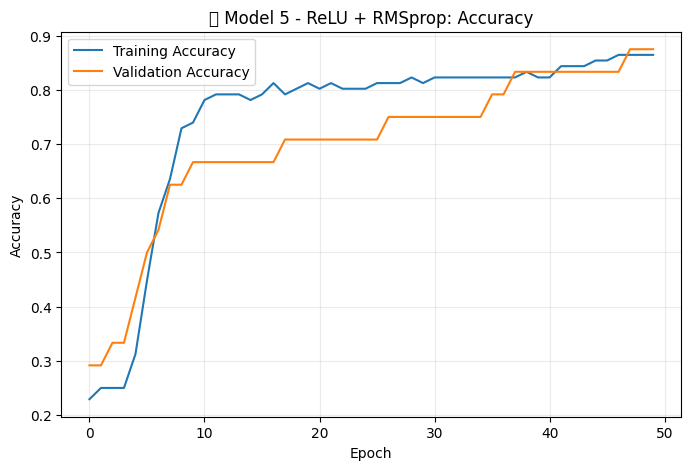

In [49]:
# 🎀 Model 5 Accuracy Curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_rmsprop.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_rmsprop.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("🎀 Model 5 - ReLU + RMSprop: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

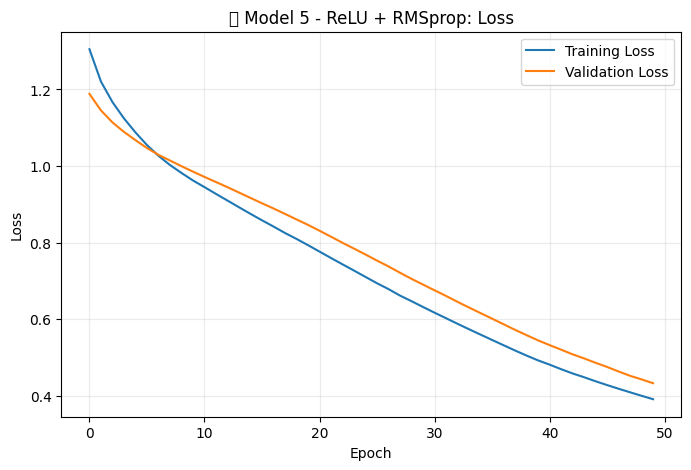

In [50]:
# 🎀 Model 5 Loss Curve

plt.figure(figsize=(8, 5))

plt.plot(
    history_rmsprop.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_rmsprop.history["val_loss"],
    label="Validation Loss"
)

plt.title("🎀 Model 5 - ReLU + RMSprop: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128150 (\N{SPARKLING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


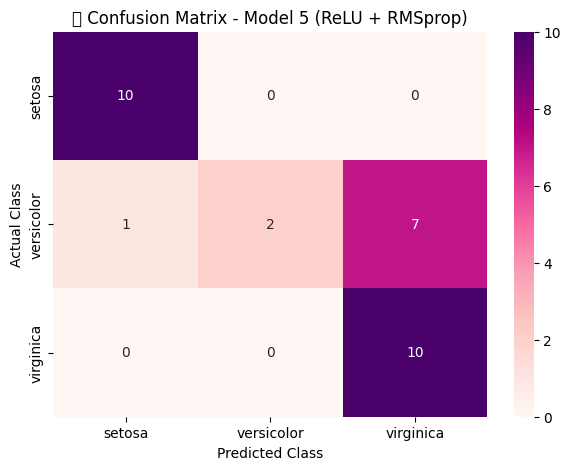

In [51]:
# 💎 Model 5 Confusion Matrix

cm_rmsprop = confusion_matrix(
    y_test,
    y_pred_rmsprop
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rmsprop,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("💖 Confusion Matrix - Model 5 (ReLU + RMSprop)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [52]:
# 💎 Final Comparison Table

results = pd.DataFrame({
    "Experiment": [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4",
        "Model 5"
    ],

    "Activation": [
        "ReLU",
        "Sigmoid",
        "Tanh",
        "ReLU",
        "ReLU"
    ],

    "Optimizer": [
        "Adam",
        "Adam",
        "Adam",
        "SGD",
        "RMSprop"
    ],

    "Test Accuracy": [
        test_accuracy,
        test_accuracy_sigmoid,
        test_accuracy_tanh,
        test_accuracy_sgd,
        test_accuracy_rmsprop
    ],

    "Precision": [
        precision,
        precision_sigmoid,
        precision_tanh,
        precision_sgd,
        precision_rmsprop
    ],

    "Recall": [
        recall,
        recall_sigmoid,
        recall_tanh,
        recall_sgd,
        recall_rmsprop
    ],

    "F1-Score": [
        f1,
        f1_sigmoid,
        f1_tanh,
        f1_sgd,
        f1_rmsprop
    ]
})

results

,Experiment,Activation,Optimizer,Test Accuracy,Precision,Recall,F1-Score
0,Model 1,ReLU,Adam,0.800000,0.875000,0.800000,0.780220
1,Model 2,Sigmoid,Adam,0.700000,0.842105,0.700000,0.623824
2,Model 3,Tanh,Adam,0.800000,0.825397,0.800000,0.791667
3,Model 4,ReLU,SGD,0.333333,0.128205,0.333333,0.185185
4,Model 5,ReLU,RMSprop,0.733333,0.832442,0.733333,0.675485


In [53]:
# 🎀 Identify the best-performing model

best_model_index = results["F1-Score"].idxmax()

best_model = results.loc[best_model_index]

print("🎀 BEST MODEL 🎀")
print("----------------")
print("Experiment:", best_model["Experiment"])
print("Activation:", best_model["Activation"])
print("Optimizer:", best_model["Optimizer"])
print("Test Accuracy:", best_model["Test Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])

🎀 BEST MODEL 🎀
----------------
Experiment: Model 3
Activation: Tanh
Optimizer: Adam
Test Accuracy: 0.800000011920929
Precision: 0.8253968253968255
Recall: 0.7999999999999999
F1-Score: 0.7916666666666666


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128149 (\N{TWO HEARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


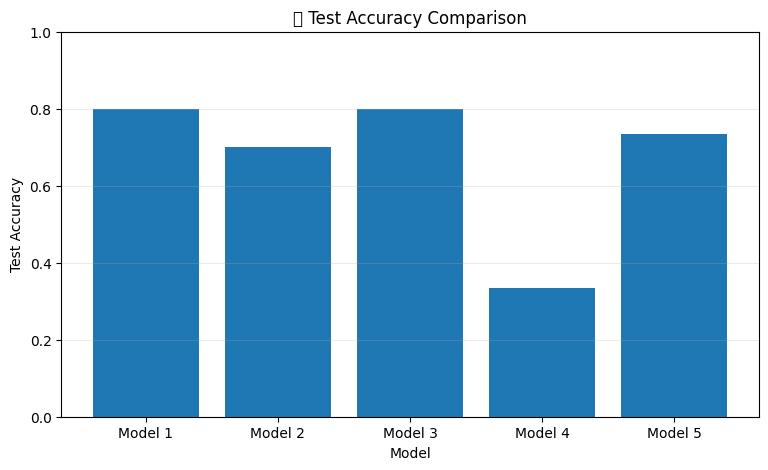

In [54]:
# 💕 Compare Test Accuracy

plt.figure(figsize=(9, 5))

plt.bar(
    results["Experiment"],
    results["Test Accuracy"]
)

plt.title("💕 Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)

plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127872 (\N{RIBBON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


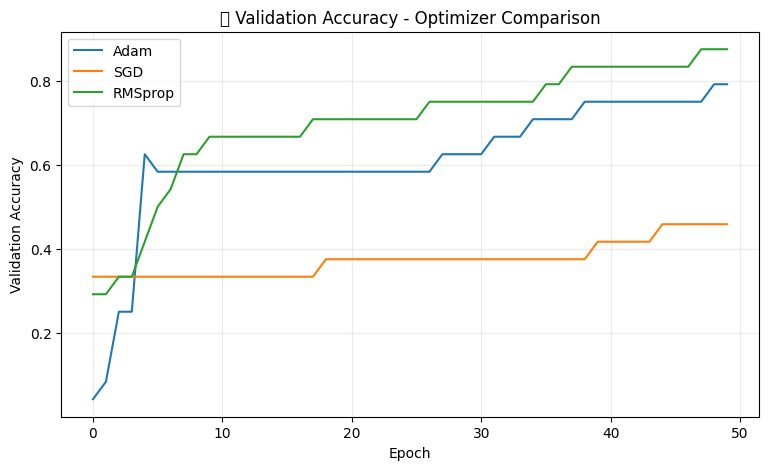

In [56]:
# 🎀 Optimizer convergence comparison

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["val_accuracy"],
    label="Adam"
)

plt.plot(
    history_sgd.history["val_accuracy"],
    label="SGD"
)

plt.plot(
    history_rmsprop.history["val_accuracy"],
    label="RMSprop"
)

plt.title("🎀 Validation Accuracy - Optimizer Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128151 (\N{GROWING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


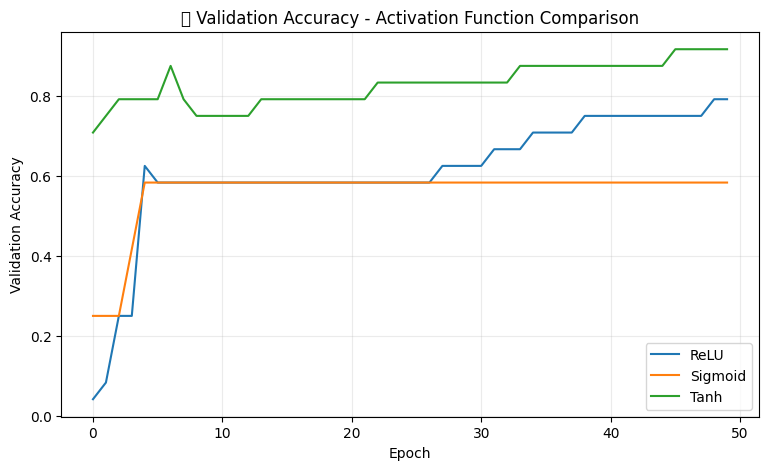

In [57]:
# 💗 Activation function comparison

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["val_accuracy"],
    label="ReLU"
)

plt.plot(
    history_sigmoid.history["val_accuracy"],
    label="Sigmoid"
)

plt.plot(
    history_tanh.history["val_accuracy"],
    label="Tanh"
)

plt.title("💗 Validation Accuracy - Activation Function Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [59]:
# 🎀 Generate a quick summary of the experimental results

print("🎀 LAB 7 EXPERIMENT SUMMARY 🎀")
print("=" * 50)

print("\n📊 Model Comparison:")
display(results)

print("\n🏆 Best Model Based on F1-Score:")
print(best_model)

print("\n💗 Dataset:")
print("Iris Dataset")

print("\n🌸 Number of Classes:", len(iris.target_names))
print("🌸 Number of Input Features:", len(iris.feature_names))
print("🌸 Training Samples:", len(X_train))
print("🌸 Testing Samples:", len(X_test))

print("\n🎀 All experiments completed successfully!")

🎀 LAB 7 EXPERIMENT SUMMARY 🎀

📊 Model Comparison:


,Experiment,Activation,Optimizer,Test Accuracy,Precision,Recall,F1-Score
0,Model 1,ReLU,Adam,0.800000,0.875000,0.800000,0.780220
1,Model 2,Sigmoid,Adam,0.700000,0.842105,0.700000,0.623824
2,Model 3,Tanh,Adam,0.800000,0.825397,0.800000,0.791667
3,Model 4,ReLU,SGD,0.333333,0.128205,0.333333,0.185185
4,Model 5,ReLU,RMSprop,0.733333,0.832442,0.733333,0.675485



🏆 Best Model Based on F1-Score:
Experiment        Model 3
Activation           Tanh
Optimizer            Adam
Test Accuracy         0.8
Precision        0.825397
Recall                0.8
F1-Score         0.791667
Name: 2, dtype: object

💗 Dataset:
Iris Dataset

🌸 Number of Classes: 3
🌸 Number of Input Features: 4
🌸 Training Samples: 120
🌸 Testing Samples: 30

🎀 All experiments completed successfully!
